# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre:** Eric Alejandro Moro Rebollo
#### **Matrícula:** A01840718

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [1]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os, io, re, itertools, logging, warnings
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
import tensorflow as tf

SEMILLA = 42
H = 12      # horizonte de pronóstico: 12 meses
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)   # Prophet imprime mucho al entrenar
logging.getLogger('prophet').setLevel(logging.WARNING)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks/MNA Maestria en Inteligencia Artificial/MNA-IA y Aprendizaje Automatico TC4058.10/Semana 9"
os.chdir(DIR)

# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [4]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

# 1a. Archivo descargado de Google Trends: "chocolate", Estados Unidos, del 01/03/2006 al 28/02/2026,
#     todas las categorías, búsqueda web. Liga con la búsqueda ya configurada:
#     https://trends.google.es/trends/explore?date=2006-03-01%202026-02-28&geo=US&q=chocolate&hl=es
#     Google lo descarga como multiTimeline.csv; se guarda en la carpeta DIR, junto a este cuaderno.
ARCHIVO = 'multiTimeline.csv'

# 1b. El CSV trae unas líneas de encabezado ("Categoría: ...") antes de los datos,
#     así que solo se leen las líneas que empiezan con una fecha AAAA-MM.
with open(ARCHIVO, encoding='utf-8-sig') as f:
    lineas = [l for l in f.read().splitlines() if re.match(r'^\s*"?\d{4}-\d{2}', l)]
dfp = pd.read_csv(io.StringIO('\n'.join(lineas)), header=None, usecols=[0, 1], names=['ds', 'y'])
dfp['y'] = pd.to_numeric(dfp['y'].astype(str).str.replace('<1', '0.5'), errors='coerce')
fechas = dfp['ds'].astype(str).str.strip(' "').str[:7]
dfp['ds'] = pd.to_datetime(fechas, format='%Y-%m') + pd.offsets.MonthEnd(0)   # día de fin de mes
dfp = dfp[(dfp['ds'] >= '2006-03-01') & (dfp['ds'] <= '2026-02-28')].reset_index(drop=True)


# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())

Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds   y
0 2006-03-31  32
1 2006-04-30  33
2 2006-05-31  31
3 2006-06-30  29
4 2006-07-31  30
            ds    y
235 2025-10-31   66
236 2025-11-30   78
237 2025-12-31  100
238 2026-01-31   75
239 2026-02-28   80


In [5]:
# Ejercicio 1c.

# ************* Inlcuye aquí tu código:*****************************

dfr = dfp.set_index('ds')
try:
    dfr = dfr.asfreq('ME')       # frecuencia mensual a fin de mes (pandas 2.2 o más reciente)
except ValueError:
    dfr = dfr.asfreq('M')        # mismo significado en versiones anteriores de pandas


# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)

Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(240, 1)
             y
ds            
2006-03-31  32
2006-04-30  33
2006-05-31  31
2006-06-30  29
2006-07-31  30
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq='ME')


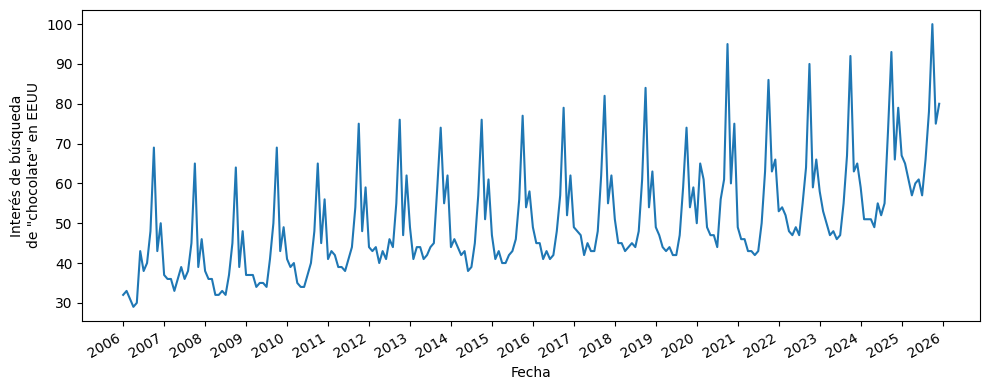

In [6]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp)+12, 12) # lista: 0,12,24,36,...,240... cada 12 meses se agregará una etiqueta del año.
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()

In [7]:
# Partición:
# Particionamos en conjunto de Prueba, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


In [8]:
# Celda de apoyo: revisión de los datos, periodos de cada conjunto y función para graficar pronósticos.

print('Meses sin dato:', int(dfr['y'].isna().sum()), '| mínimo:', dfr['y'].min(), '| máximo:', dfr['y'].max())
for nombre, d in [('Entrenamiento', trainR), ('Validación', valR), ('Prueba', testR)]:
    print(f'{nombre:13s}: {d.index.min():%Y-%m} a {d.index.max():%Y-%m} ({len(d)} meses)')

MESES = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
patron = trainR['y'].groupby(trainR.index.month).mean()
patron.index = MESES
print('\nPromedio del interés por mes (solo entrenamiento):')
print(patron.round(1).to_string())

def graficar_pronostico(pronosticos, titulo, contexto=None, real=None):
    """pronosticos: diccionario {etiqueta: valores pronosticados}."""
    contexto = trainR if contexto is None else contexto
    real = valR if real is None else real
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(contexto['y'][-48:], color='gray', label='Histórico (últimos 4 años)')
    ax.plot(real['y'], 'o-', color='black', label='Real')
    for etiqueta, valores in pronosticos.items():
        ax.plot(real.index, np.asarray(valores), 'o--', label=etiqueta)
    ax.set_title(titulo)
    ax.set_ylabel('Interés de búsqueda (0-100)')
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

Meses sin dato: 0 | mínimo: 29 | máximo: 100
Entrenamiento: 2006-03 a 2024-02 (216 meses)
Validación   : 2024-03 a 2025-02 (12 meses)
Prueba       : 2025-03 a 2026-02 (12 meses)

Promedio del interés por mes (solo entrenamiento):
ene    51.3
feb    59.4
mar    45.4
abr    44.3
may    43.7
jun    40.2
jul    40.8
ago    41.1
sep    41.2
oct    45.9
nov    56.2
dic    77.3


**Sobre los datos (Ejercicio 1).** Google Trends no entrega el número de búsquedas, sino un índice relativo de 0 a 100. Cada mes se mide como proporción del total de búsquedas hechas en Google en ese momento, y después todo se escala para que el mes con más interés del periodo valga 100 (Google News Initiative, s.f.). Esto tiene dos consecuencias prácticas:

* Si se descarga otro rango de fechas, toda la serie se reescala. Por eso se respetó exactamente el periodo del 1 de marzo de 2006 al 28 de febrero de 2026.
* Google calcula el índice con una muestra de las búsquedas, así que dos descargas del mismo periodo pueden diferir en uno o dos puntos. Todos los modelos se entrenan con el mismo archivo para que la comparación sea justa.

La serie tiene 240 meses. La partición respeta el orden del tiempo: los últimos 12 meses son la prueba, los 12 anteriores la validación y el resto el entrenamiento. En series de tiempo no se revuelven los datos, porque eso dejaría que el modelo aprenda del futuro para predecir el pasado (Hyndman y Athanasopoulos, 2021, sec. 5.8). La celda anterior imprime el promedio del interés por mes con los datos de entrenamiento, que deja ver el patrón estacional que los modelos tienen que capturar.

**Lo que muestran los datos descargados.** El promedio por mes en entrenamiento confirma el patrón: diciembre es el mes más alto (77.3), seguido de febrero (59.4) y noviembre (56.2), y junio es el más bajo (40.2). La gráfica también deja ver una tendencia creciente: los meses bajos pasaron de alrededor de 30 puntos en 2006 a alrededor de 50 en 2024, y los picos de diciembre, de entre 64 y 69 en 2006–2010, a entre 86 y 95 desde 2020. El máximo de toda la serie (100) cae en diciembre de 2025, ya dentro del conjunto de prueba.

El archivo descargado empieza en enero de 2006; el filtro del inciso 1b deja solo los 240 meses pedidos. Como el mes con valor 100 está dentro del periodo, la escala es la misma que si la descarga hubiera empezado en marzo de 2006.

* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjnuto de Prueba (Test).**

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

++++++++ Inicia la sección de agregar texto: +++++++++++

El MAE promedia el error en valor absoluto, $MAE=\frac{1}{n}\sum|y_t-\hat y_t|$, mientras que el MSE promedia el error al cuadrado, $MSE=\frac{1}{n}\sum(y_t-\hat y_t)^2$.

**Ventajas del MAE frente al MSE:**
* **Se interpreta directo.** Está en las mismas unidades que la serie, puntos del índice de Google Trends. Un MAE de 5 significa que el pronóstico se equivoca en promedio 5 puntos al mes. El MSE queda en "puntos al cuadrado", que no tiene lectura de negocio.
* **Es más robusto a valores atípicos.** Cada error pesa en proporción a su tamaño. En Google Trends puede haber meses con picos aislados, por una noticia o una campaña, y con el MSE ese solo mes dominaría la evaluación.
* **Todos los errores cuentan igual.** Si el costo de equivocarse crece de forma lineal, el MAE describe mejor el desempeño real.

**Desventajas del MAE frente al MSE:**
* **No castiga más los errores grandes.** Fallar por 20 puntos un mes cuenta igual que fallar por 10 en dos meses. Si lo grave es no anticipar el pico de febrero, el MSE (o el RMSE) señala mejor ese problema.
* **Es menos cómodo para optimizar.** El valor absoluto no es derivable en cero, mientras que el error cuadrático es suave. Por eso muchos métodos, como ARIMA, se ajustan minimizando errores cuadráticos o la verosimilitud gaussiana, y la métrica de evaluación no coincide con la de entrenamiento.
* **Depende de la escala, igual que el MSE.** No sirve para comparar series en unidades distintas; para eso se usan métricas relativas como el MAPE o el MASE (Hyndman y Athanasopoulos, 2021, sec. 5.8).

++++++++ Termina la sección de agregar texto. +++++++++++

In [9]:
# Ejercicio 2b:

# ************* Inlcuye aquí tu código:*****************************
# Incluye todas las celdas que consideres adecuadas.

# Modelo ingenuo: los 12 meses de validación se pronostican con el último valor observado en entrenamiento.
predNaive = pd.Series(trainR['y'].iloc[-1], index=valR.index)
maeNaive = mean_absolute_error(valR['y'], predNaive)

# Referencia adicional, ingenuo estacional: cada mes se pronostica con el mismo mes del año anterior.
predNaiveEst = pd.Series(trainR['y'].iloc[-12:].values, index=valR.index)
maeNaiveEst = mean_absolute_error(valR['y'], predNaiveEst)

print('Último valor de entrenamiento (%s): %.0f' % (f'{trainR.index[-1]:%Y-%m}', trainR['y'].iloc[-1]))
print('Referencia, ingenuo estacional: MAE = %.3f' % maeNaiveEst)


# *********** Aquí termina la sección de agregar código *************


print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)

Último valor de entrenamiento (2024-02): 65
Referencia, ingenuo estacional: MAE = 3.917

Error-modelo-Naive : MAE: 12.333


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++

El modelo ingenuo obtuvo un MAE de 12.333: en promedio, su pronóstico se equivocó por poco más de 12 puntos del índice cada mes. En validación el interés promedio fue de 61.2 puntos, así que el error equivale a cerca del 20 % del nivel de la serie. Para un pronóstico mensual es un error grande.

La causa se ve en la gráfica. El último mes de entrenamiento es febrero de 2024, con 65 puntos, y como febrero es un mes alto por San Valentín, el modelo repite un valor elevado todo el año. De abril a octubre sobrestima entre 10 y 16 puntos, porque el interés real estuvo entre 49 y 55; en cambio, en diciembre se queda 28 puntos abajo, porque el interés llegó a 93. Solo acierta en enero (66 contra 65), y de pura casualidad.

El ingenuo estacional, que copia el mismo mes del año anterior, baja el error a 3.917, casi una tercera parte. Eso confirma que la estacionalidad es lo que más pesa en esta serie: un modelo útil tiene que saber que diciembre y febrero son altos y que el verano es bajo. Para la actividad, 12.333 es el piso que cualquier modelo tiene que mejorar, pero la referencia que de verdad hay que superar está más cerca de 3.9.

++++++++ Termina la sección de agregar texto. +++++++++++

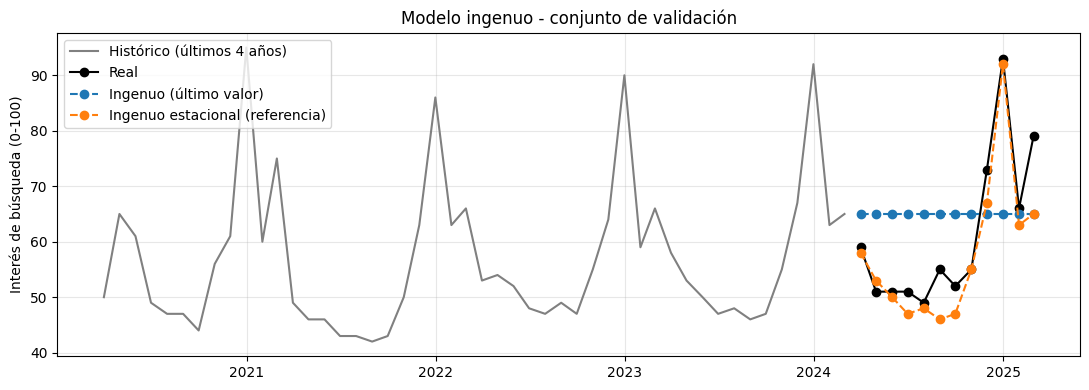

In [10]:
# Ejercicio 2d:

# ************* Inlcuye aquí tu código:*****************************

graficar_pronostico({'Ingenuo (último valor)': predNaive, 'Ingenuo estacional (referencia)': predNaiveEst},
                    'Modelo ingenuo - conjunto de validación')


# *********** Aquí termina la sección de agregar código *************

# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

**Cómo se construyó el modelo ARIMA.** Siguiendo la recomendación de empezar con un modelo sencillo:

1. **Estacionariedad.** ARIMA necesita una serie estacionaria (media y varianza estables). La prueba de Dickey-Fuller aumentada se aplica a la serie original, a su primera diferencia y a su diferencia estacional; un p-valor menor a 0.05 indica estacionariedad. Esto orienta los valores de $d$ (diferencias regulares) y $D$ (diferencias estacionales).
2. **ACF y PACF.** Las gráficas de autocorrelación muestran qué rezagos influyen. Picos en los rezagos 12, 24 y 36 confirman un ciclo anual.
3. **Modelo base ARIMA(1,1,1)**, sin estacionalidad, como punto de partida.
4. **SARIMA(p,d,q)(P,D,Q,12).** Es el mismo ARIMA con una parte estacional de periodo 12, que modela la relación de cada mes con el mismo mes del año anterior. Se prueban 144 combinaciones y se elige la de menor MAE en validación; el AIC se muestra como referencia (Hyndman y Athanasopoulos, 2021, cap. 9).

Cuidado: elegir entre 144 modelos con solo 12 meses de validación puede ajustarse de más a esos 12 meses. Por eso el desempeño final se confirma con el conjunto de prueba en el Ejercicio 6.

/tmp/ipykernel_6122/1481875303.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f'{nombre:28s} p-valor ADF = {adfuller(s)[1]:.4f}')
/tmp/ipykernel_6122/1481875303.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f'{nombre:28s} p-valor ADF = {adfuller(s)[1]:.4f}')
/tmp/ipykernel_6122/1481875303.py:11: FutureWarning: adfuller currently returns a plain tu

Serie original               p-valor ADF = 0.8433
Primera diferencia           p-valor ADF = 0.0000
Diferencia estacional (12)   p-valor ADF = 0.0000


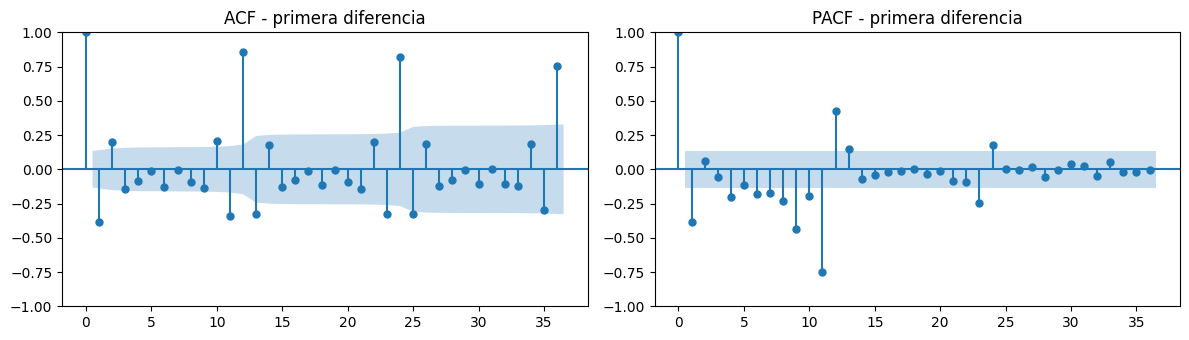

In [11]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Paso 1. ¿La serie es estacionaria? Prueba de Dickey-Fuller aumentada, solo con entrenamiento.
#         p-valor < 0.05 indica que la serie es estacionaria.
serie_tr = trainR['y']
for nombre, s in [('Serie original', serie_tr),
                  ('Primera diferencia', serie_tr.diff().dropna()),
                  ('Diferencia estacional (12)', serie_tr.diff(12).dropna())]:
    print(f'{nombre:28s} p-valor ADF = {adfuller(s)[1]:.4f}')

# Autocorrelación (ACF) y autocorrelación parcial (PACF) de la serie diferenciada
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(serie_tr.diff().dropna(), lags=36, ax=ax[0], title='ACF - primera diferencia')
plot_pacf(serie_tr.diff().dropna(), lags=36, ax=ax[1], method='ywm', title='PACF - primera diferencia')
plt.tight_layout()
plt.show()

In [12]:
# Paso 2. Modelo sencillo ARIMA(1,1,1), sin componente estacional.
def pronostico_arima(serie, orden, orden_est=(0, 0, 0, 0), h=H):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        modelo = ARIMA(serie, order=orden, seasonal_order=orden_est).fit()
    return modelo.forecast(steps=h), modelo

pred_simple, _ = pronostico_arima(trainR['y'], (1, 1, 1))
print('ARIMA(1,1,1) sin estacionalidad: MAE validación = %.3f' % mean_absolute_error(valR['y'], pred_simple))

# Paso 3. Búsqueda de SARIMA(p,d,q)(P,D,Q,12), eligiendo por MAE en validación (tarda unos minutos).
resultados_arima = []
for p, d, q, P, D, Q in itertools.product([0, 1, 2], [0, 1], [0, 1, 2], [0, 1], [0, 1], [0, 1]):
    try:
        pred, mod = pronostico_arima(trainR['y'], (p, d, q), (P, D, Q, 12))
        if not np.isfinite(pred).all():
            continue
        resultados_arima.append({'orden': (p, d, q), 'orden_est': (P, D, Q, 12), 'AIC': mod.aic,
                                 'MAE val': mean_absolute_error(valR['y'], pred)})
    except Exception:
        continue

tabla_arima = pd.DataFrame(resultados_arima).sort_values('MAE val').reset_index(drop=True)
print('\nModelos probados:', len(tabla_arima))
print(tabla_arima.head(10).round(3).to_string())

mejor_arima = tabla_arima.iloc[0]
predARIMA, modelo_arima = pronostico_arima(trainR['y'], mejor_arima['orden'], mejor_arima['orden_est'])
nombre_arima = 'SARIMA%s%s' % (mejor_arima['orden'], mejor_arima['orden_est'])
print('\nModelo elegido:', nombre_arima)


maeARIMA = mean_absolute_error(valR['y'], predARIMA)

ARIMA(1,1,1) sin estacionalidad: MAE validación = 11.701

Modelos probados: 144
       orden      orden_est       AIC  MAE val
0  (2, 1, 2)  (0, 1, 0, 12)  1153.645    3.237
1  (0, 1, 1)  (0, 1, 0, 12)  1172.200    3.250
2  (2, 1, 1)  (0, 1, 0, 12)  1152.055    3.250
3  (1, 1, 2)  (0, 1, 0, 12)  1154.344    3.283
4  (1, 1, 1)  (0, 1, 0, 12)  1157.100    3.304
5  (0, 1, 2)  (0, 1, 0, 12)  1171.906    3.354
6  (2, 1, 0)  (0, 1, 0, 12)  1181.181    3.433
7  (1, 1, 0)  (0, 1, 0, 12)  1182.007    3.529
8  (2, 1, 1)  (1, 0, 0, 12)  1268.371    3.532
9  (2, 1, 0)  (1, 0, 0, 12)  1267.441    3.543

Modelo elegido: SARIMA(2, 1, 2)(0, 1, 0, 12)


In [13]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 3.237


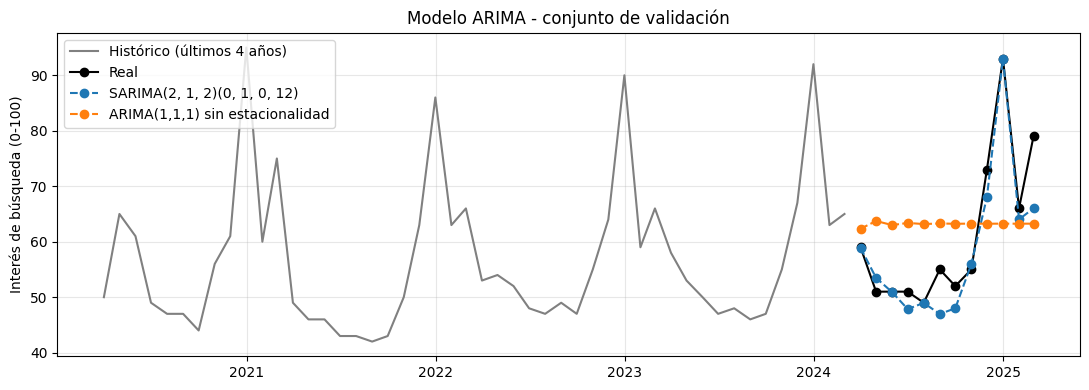

In [14]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

graficar_pronostico({nombre_arima: predARIMA, 'ARIMA(1,1,1) sin estacionalidad': pred_simple},
                    'Modelo ARIMA - conjunto de validación')


# *********** Aquí termina la sección de agregar código *************

**Comentarios del modelo ARIMA.**

* La prueba ADF confirma que la serie original no es estacionaria (p-valor de 0.8433), mientras que la primera diferencia y la diferencia estacional sí lo son (p-valor de 0.0000 en ambos casos). En la ACF de la primera diferencia sobresalen los rezagos 12, 24 y 36, con valores cercanos a 0.86, 0.82 y 0.75, que bajan muy despacio. Es la huella de un ciclo anual fuerte, y por eso hace falta la diferencia estacional.
* El modelo sencillo ARIMA(1,1,1) sin estacionalidad tuvo un MAE de 11.701, apenas mejor que el ingenuo (12.333). En la gráfica su pronóstico es casi una línea plana alrededor de 63, porque no sabe nada del ciclo anual.
* Al agregar la parte estacional, el error baja a 3.237 con SARIMA(2,1,2)(0,1,0,12). Los ocho mejores modelos de la búsqueda tienen la misma parte estacional (0,1,0,12), es decir, una diferencia de 12 meses sin más términos, y sus MAE van de 3.237 a 3.529. Lo que más ayuda es esa diferencia estacional; los términos p y q solo afinan el resultado.
* Por AIC, el mejor de la tabla sería SARIMA(2,1,1)(0,1,0,12), con 1152.055 contra 1153.645 del elegido, y su MAE de validación es 3.250, prácticamente el mismo. Los dos criterios apuntan al mismo tipo de modelo. Los modelos con D = 0 tienen un AIC cercano a 1268, pero ese valor no se puede comparar con los de D = 1, porque al diferenciar cambian los datos sobre los que se calcula la verosimilitud (Hyndman y Athanasopoulos, 2021, sec. 9.6).
* En la gráfica, el SARIMA sigue bien el valle del verano y clava el pico de diciembre (93 puntos). Donde más falla es en febrero de 2025, cuando el real fue 79 y el modelo esperaba alrededor de 66, y en agosto de 2024 (55 contra cerca de 47).

# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

**Cómo se construyó el modelo Prophet.** Prophet descompone la serie en tendencia, estacionalidad y efectos de días especiales: $y(t)=g(t)+s(t)+h(t)+\varepsilon_t$ (Taylor y Letham, 2018). La tendencia $g(t)$ puede cambiar de pendiente en ciertos puntos (*changepoints*), y la estacionalidad anual $s(t)$ se modela con series de Fourier.

* Como los datos son mensuales, se desactivan las estacionalidades semanal y diaria, que no se pueden estimar con un dato por mes.
* Primero se entrena con los parámetros por defecto y después se prueba una rejilla de 16 combinaciones:
  * `changepoint_prior_scale`: qué tanto puede cambiar la tendencia. Valores altos la hacen más flexible, con riesgo de sobreajuste.
  * `seasonality_prior_scale`: qué tan fuerte puede ser la estacionalidad.
  * `seasonality_mode`: si el patrón anual se suma a la tendencia (aditivo) o crece con ella (multiplicativo).
* Se elige la combinación con menor MAE en validación. La gráfica de componentes muestra la tendencia y el patrón anual que aprendió el modelo.

In [15]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

def pronostico_prophet(df_entrena, fechas, **params):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, **params)
    m.fit(df_entrena)
    return m.predict(pd.DataFrame({'ds': fechas}))['yhat'].values, m

# Paso 1. Prophet con sus parámetros por defecto
pred_prophet_base, _ = pronostico_prophet(trainP, valP['ds'])
print('Prophet por defecto: MAE validación = %.3f' % mean_absolute_error(valP['y'], pred_prophet_base))

# Paso 2. Búsqueda pequeña de hiperparámetros, eligiendo por MAE en validación
rejilla = {'changepoint_prior_scale': [0.01, 0.05, 0.1, 0.5],
           'seasonality_prior_scale': [1.0, 10.0],
           'seasonality_mode': ['additive', 'multiplicative']}
resultados_prophet = []
for valores in itertools.product(*rejilla.values()):
    params = dict(zip(rejilla.keys(), valores))
    pred, _ = pronostico_prophet(trainP, valP['ds'], **params)
    resultados_prophet.append({**params, 'MAE val': mean_absolute_error(valP['y'], pred)})

tabla_prophet = pd.DataFrame(resultados_prophet).sort_values('MAE val').reset_index(drop=True)
print(tabla_prophet.head(8).round(3).to_string())

mejores_params_prophet = tabla_prophet.drop(columns='MAE val').iloc[0].to_dict()
predProphet, modelo_prophet = pronostico_prophet(trainP, valP['ds'], **mejores_params_prophet)
print('\nParámetros elegidos:', mejores_params_prophet)


maeProphet = mean_absolute_error(valP['y'], predProphet)

Prophet por defecto: MAE validación = 4.140
   changepoint_prior_scale  seasonality_prior_scale seasonality_mode  MAE val
0                     0.01                      1.0   multiplicative    3.081
1                     0.01                     10.0   multiplicative    3.088
2                     0.01                      1.0         additive    3.680
3                     0.01                     10.0         additive    3.692
4                     0.10                      1.0   multiplicative    3.780
5                     0.10                     10.0   multiplicative    3.786
6                     0.05                      1.0   multiplicative    3.809
7                     0.05                     10.0   multiplicative    3.816

Parámetros elegidos: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 1.0, 'seasonality_mode': 'multiplicative'}


In [16]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 3.081


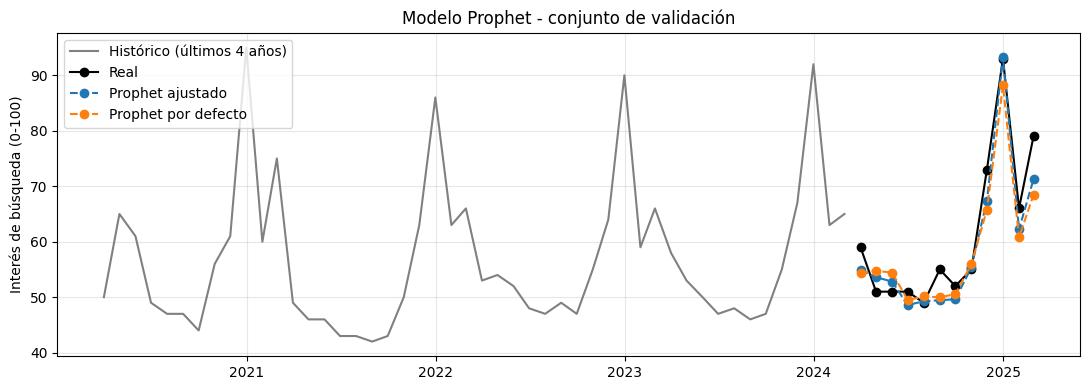

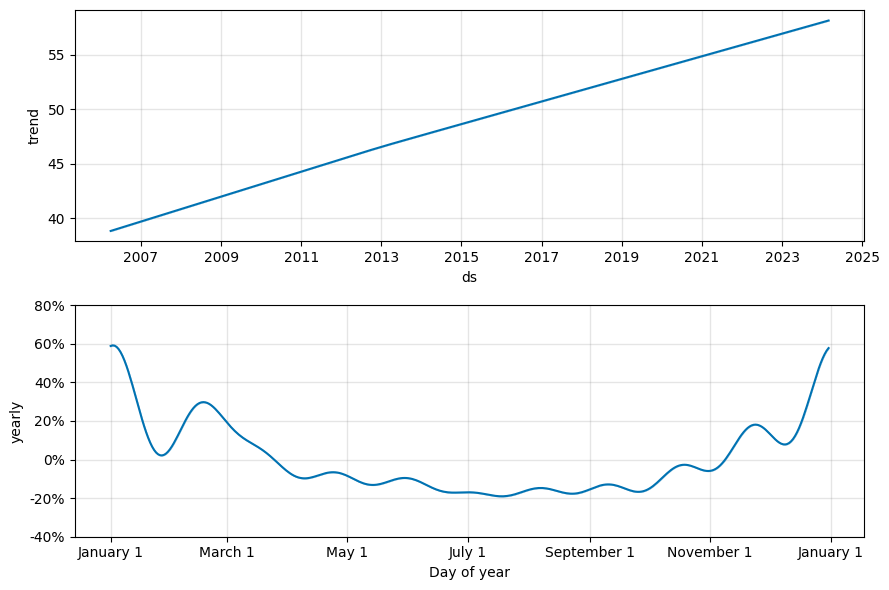

In [17]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

graficar_pronostico({'Prophet ajustado': predProphet, 'Prophet por defecto': pred_prophet_base},
                    'Modelo Prophet - conjunto de validación')

# Componentes que aprendió el modelo: tendencia y estacionalidad anual
modelo_prophet.plot_components(modelo_prophet.predict(trainP[['ds']]))
plt.show()


# *********** Aquí termina la sección de agregar código *************

**Comentarios del modelo Prophet.**

* Con los parámetros por defecto, Prophet tuvo un MAE de 4.140, todavía peor que el ingenuo estacional (3.917). Con el ajuste bajó a 3.081, el menor de todos los modelos en validación.
* Lo que más influyó fue el modo multiplicativo junto con `changepoint_prior_scale = 0.01`. Las dos primeras filas de la tabla solo cambian en `seasonality_prior_scale` (1.0 y 10.0) y su MAE casi no se mueve (3.081 y 3.088), así que ese parámetro importa poco aquí. En cambio, con el mismo `changepoint_prior_scale = 0.01`, pasar de aditivo a multiplicativo baja el error de 3.680 a 3.081.
* El modo multiplicativo es congruente con la gráfica de la serie: los picos de diciembre crecieron junto con el nivel general, de entre 64 y 69 puntos en 2006–2010 a entre 86 y 95 desde 2020. Es decir, la temporada alta no suma siempre los mismos puntos, sino un porcentaje del nivel.
* Un `changepoint_prior_scale` de 0.01 hace la tendencia muy rígida. En la gráfica de componentes es prácticamente una recta que sube de cerca de 39 a cerca de 58 entre 2006 y 2024. Funcionó bien en validación, pero también significa que el modelo casi no reacciona a cambios recientes de nivel, algo que pesa en el Ejercicio 6.
* La componente anual sube cerca de 60 % al cierre de diciembre y entre 20 y 30 % a finales de febrero, y baja entre 10 y 20 % de mayo a septiembre. Como cada dato está fechado el último día del mes, el pico de diciembre aparece pegado al 1 de enero y el de febrero cerca del 1 de marzo; no son picos de enero ni de marzo.
* En la gráfica de validación, el modelo ajustado sigue la forma del año y acierta el pico de diciembre. Sus errores más visibles son marzo de 2024 (59 real contra cerca de 54) y febrero de 2025 (79 contra cerca de 71).

# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

**Cómo se construyó el modelo LSTM.** Una LSTM es una red neuronal recurrente que procesa la serie en orden y usa compuertas para decidir qué información conservar y cuál olvidar. Así evita el problema del gradiente que se desvanece de las redes recurrentes simples y puede recordar patrones de varios meses atrás (Hochreiter y Schmidhuber, 1997; Géron, 2022, cap. 15).

1. **`df_tv`** une entrenamiento y validación, como pide la actividad.
2. **Escalado a [0, 1]** con `MinMaxScaler`, ajustado solo con entrenamiento para no filtrar información de validación. Al final las predicciones se regresan a la escala original.
3. **Secuencias:** cada muestra son los últimos 12 o 24 meses (ventana) y su objetivo es el mes siguiente. Las muestras cuyo objetivo cae en los 12 meses de validación forman la partición de validación; el resto, la de entrenamiento.
4. **Entrenamiento** con parada temprana: se detiene cuando el error de validación deja de mejorar durante 30 épocas y conserva los mejores pesos. Se prueban 4 configuraciones (ventana de 12 o 24 meses, 32 o 64 unidades).
5. **Pronóstico recursivo de 12 meses.** Para que la comparación con el ingenuo, ARIMA y Prophet sea justa, la LSTM pronostica los 12 meses de validación solo con datos de entrenamiento: predice un mes, lo agrega a la ventana y con eso predice el siguiente. La tabla también muestra el MAE "un paso", que usa los valores reales de cada mes anterior. Ese error es más bajo, pero no es comparable, porque en la práctica no se conocen los meses futuros.

Las redes neuronales parten de pesos aleatorios. Aunque se fija la semilla, los resultados pueden variar un poco entre ejecuciones o equipos.

In [18]:
# Ejercicio 5a - LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Entrenamiento y validación juntos, como pide la actividad
df_tv = pd.concat([trainR, valR])
n_val = len(valR)

# Escalado entre 0 y 1, ajustado SOLO con entrenamiento para no filtrar información de validación
escalador = MinMaxScaler().fit(trainR[['y']])
serie_tv = escalador.transform(df_tv[['y']]).ravel()

def crear_secuencias(serie, ventana):
    """Cada muestra son 'ventana' meses consecutivos y su objetivo es el mes siguiente."""
    X = np.array([serie[i:i + ventana] for i in range(len(serie) - ventana)])
    return X[..., np.newaxis], serie[ventana:]

def construir_lstm(ventana, unidades):
    modelo = tf.keras.Sequential([tf.keras.Input(shape=(ventana, 1)),
                                  tf.keras.layers.LSTM(unidades),
                                  tf.keras.layers.Dense(1)])
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mae')
    return modelo

def pronostico_recursivo(modelo, historia, ventana, h=H):
    """Pronostica h meses: cada predicción se agrega a la ventana para predecir el mes siguiente."""
    ventana_actual = list(historia[-ventana:])
    preds = []
    for _ in range(h):
        x = np.array(ventana_actual[-ventana:], dtype='float32').reshape(1, ventana, 1)
        p = float(modelo(x, training=False).numpy()[0, 0])
        preds.append(p)
        ventana_actual.append(p)
    return np.array(preds)

resultados_lstm = []
for ventana, unidades in itertools.product([12, 24], [32, 64]):
    X, y = crear_secuencias(serie_tv, ventana)
    X_tr, y_tr, X_v, y_v = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]   # partición train / val
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo = construir_lstm(ventana, unidades)
    parada = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)
    hist = modelo.fit(X_tr, y_tr, validation_data=(X_v, y_v), epochs=300, batch_size=16,
                      verbose=0, callbacks=[parada])
    pred = escalador.inverse_transform(
        pronostico_recursivo(modelo, serie_tv[:-n_val], ventana).reshape(-1, 1)).ravel()
    un_paso = escalador.inverse_transform(modelo.predict(X_v, verbose=0)).ravel()
    resultados_lstm.append({'ventana': ventana, 'unidades': unidades,
                            'épocas': int(np.argmin(hist.history['val_loss'])) + 1,
                            'MAE val (12 meses)': mean_absolute_error(valR['y'], pred),
                            'MAE val (un paso)': mean_absolute_error(valR['y'], un_paso),
                            'pred': pred})

tabla_lstm = pd.DataFrame(resultados_lstm).sort_values('MAE val (12 meses)').reset_index(drop=True)
print(tabla_lstm.drop(columns='pred').round(3).to_string())

cfg = tabla_lstm.iloc[0]
predLSTM = cfg['pred']
print('\nConfiguración elegida: ventana = %d meses, %d unidades, %d épocas'
      % (cfg['ventana'], cfg['unidades'], cfg['épocas']))


maeLSTM = mean_absolute_error(valR['y'], predLSTM)

   ventana  unidades  épocas  MAE val (12 meses)  MAE val (un paso)
0       24        32     104               3.422              3.358
1       12        64      51               3.457              3.637
2       24        64      81               3.534              3.408
3       12        32      47               3.560              3.670

Configuración elegida: ventana = 24 meses, 32 unidades, 104 épocas


In [19]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 3.422


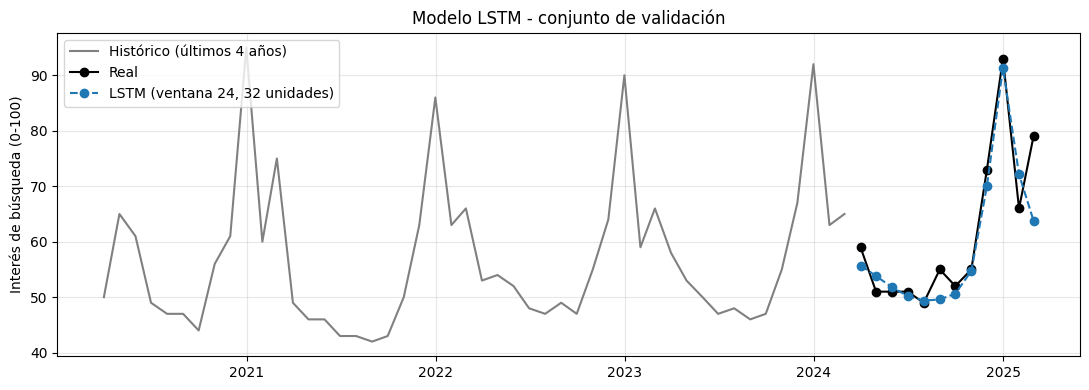

In [20]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Inlcuye aquí tu código:*****************************

etiqueta = 'LSTM (ventana %d, %d unidades)' % (cfg['ventana'], cfg['unidades'])
graficar_pronostico({etiqueta: predLSTM}, 'Modelo LSTM - conjunto de validación')


# *********** Aquí termina la sección de agregar código *************

**Comentarios del modelo LSTM.**

* La mejor configuración fue una ventana de 24 meses con 32 unidades, que se detuvo en la época 104 y obtuvo un MAE de 3.422. Las cuatro configuraciones quedaron entre 3.422 y 3.560, una diferencia de apenas 0.14 puntos. Como la red parte de pesos aleatorios, otra corrida podría cambiar el orden. La ventana de 24 meses tiene una pequeña ventaja, posiblemente porque ve dos ciclos anuales completos.
* El MAE de un paso no siempre fue menor que el recursivo: con ventana de 24 meses sí (3.358 contra 3.422), pero con ventana de 12 fue al revés (3.637 contra 3.457 y 3.670 contra 3.560). Con solo 12 meses de validación estas diferencias son pequeñas, y muestran que el error del pronóstico recursivo no se acumuló mucho: la red aprendió bien la forma del año.
* En la gráfica, la LSTM sigue el valle del verano y casi alcanza el pico de diciembre (cerca de 91 contra 93). Donde se equivoca es en el cierre: pronostica enero de 2025 más alto que febrero (cerca de 72 y 64), cuando en realidad fue al revés (66 y 79).
* La LSTM no superó a SARIMA ni a Prophet. Con 228 meses tiene poco más de 200 ejemplos para aprender, mientras que los modelos estadísticos ya traen la estacionalidad como parte de su estructura.

# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

**Cómo se obtiene el desempeño final.** Se elige el modelo con menor MAE en validación entre los cuatro que pide la actividad. Después se vuelve a entrenar con entrenamiento + validación (228 meses), con los mismos hiperparámetros encontrados, y se pronostican los 12 meses de prueba. En el caso de la LSTM, al no haber datos de validación para la parada temprana, se usa el mismo número de épocas que dio el mejor resultado. El conjunto de prueba se usa una sola vez, solo para medir; nunca para decidir.

In [21]:
# Ejercicio 6 - mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Comparación en validación de los cuatro modelos que pide la actividad
comparacion = pd.Series({'Ingenuo': maeNaive, 'ARIMA': maeARIMA,
                         'Prophet': maeProphet, 'LSTM': maeLSTM}).sort_values()
print('MAE en validación:')
print(comparacion.round(3).to_string())
print('(Referencia, ingenuo estacional: %.3f)' % maeNaiveEst)
MEJOR = comparacion.index[0]
print('\nMejor modelo:', MEJOR)

# El mejor modelo se reentrena con entrenamiento + validación y pronostica los 12 meses de prueba
tvR, tvP = dfr[:-12], dfp[:-12]
if MEJOR == 'Ingenuo':
    predMejor = np.repeat(tvR['y'].iloc[-1], H)
elif MEJOR == 'ARIMA':
    predMejor, _ = pronostico_arima(tvR['y'], mejor_arima['orden'], mejor_arima['orden_est'])
elif MEJOR == 'Prophet':
    predMejor, _ = pronostico_prophet(tvP, testP['ds'], **mejores_params_prophet)
else:
    escalador_f = MinMaxScaler().fit(tvR[['y']])
    serie_f = escalador_f.transform(tvR[['y']]).ravel()
    X, y = crear_secuencias(serie_f, int(cfg['ventana']))
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo_f = construir_lstm(int(cfg['ventana']), int(cfg['unidades']))
    modelo_f.fit(X, y, epochs=int(cfg['épocas']), batch_size=16, verbose=0)   # mismas épocas que en validación
    predMejor = escalador_f.inverse_transform(
        pronostico_recursivo(modelo_f, serie_f, int(cfg['ventana'])).reshape(-1, 1)).ravel()


maeMejor = mean_absolute_error(testR['y'], predMejor)

MAE en validación:
Prophet     3.081
ARIMA       3.237
LSTM        3.422
Ingenuo    12.333
(Referencia, ingenuo estacional: 3.917)

Mejor modelo: Prophet


In [22]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 8.353


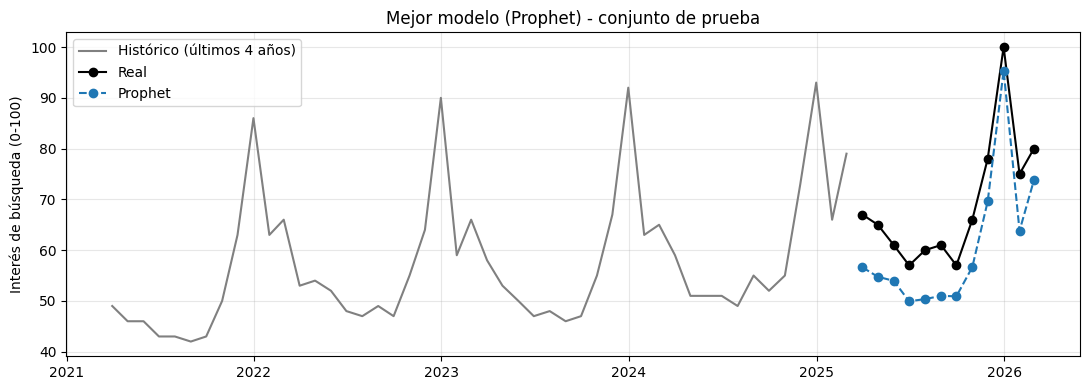

ds          2025-03  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02
Real           67.0     65.0     61.0     57.0     60.0     61.0     57.0     66.0     78.0    100.0     75.0     80.0
Pronóstico     56.6     54.8     54.0     49.9     50.4     51.0     50.9     56.7     69.6     95.4     63.8     73.8


In [23]:
# Pronóstico del mejor modelo contra los valores reales del conjunto de prueba
graficar_pronostico({MEJOR: predMejor}, f'Mejor modelo ({MEJOR}) - conjunto de prueba', contexto=tvR, real=testR)
print(pd.DataFrame({'Real': testR['y'].values, 'Pronóstico': np.round(predMejor, 1)},
                   index=testR.index.strftime('%Y-%m')).T.to_string())

In [24]:
# Revisión adicional del año de prueba: cambio contra años anteriores y referencias simples.
# Solo usa los datos (no entrena modelos), así que se puede correr después de la partición.
anio_previo = dfr['y'][-36:-24].values     # mar-2023 a feb-2024
anio_val = dfr['y'][-24:-12].values        # mar-2024 a feb-2025 (validación)
anio_prueba = testR['y'].values            # mar-2025 a feb-2026 (prueba)

print('Cambio promedio contra el mismo mes del año anterior:')
print('  Año de validación: %+.2f puntos' % (anio_val - anio_previo).mean())
print('  Año de prueba:     %+.2f puntos' % (anio_prueba - anio_val).mean())
print('\nReferencias en prueba (con entrenamiento + validación):')
print('  Ingenuo (último valor): MAE = %.3f' % mean_absolute_error(anio_prueba, np.repeat(anio_val[-1], H)))
print('  Ingenuo estacional:     MAE = %.3f' % mean_absolute_error(anio_prueba, anio_val))

Cambio promedio contra el mismo mes del año anterior:
  Año de validación: +3.58 puntos
  Año de prueba:     +7.75 puntos

Referencias en prueba (con entrenamiento + validación):
  Ingenuo (último valor): MAE = 13.750
  Ingenuo estacional:     MAE = 7.750


**Comentarios del Ejercicio 6.**

* En validación, los tres modelos quedaron muy cerca: Prophet 3.081, ARIMA 3.237 y LSTM 3.422. Los tres le ganan con claridad al ingenuo (12.333) y también al ingenuo estacional (3.917). Prophet fue el mejor, pero su ventaja sobre ARIMA es de apenas 0.156 puntos, medida con solo 12 meses.
* Reentrenado con los 228 meses de entrenamiento y validación, Prophet obtuvo un MAE de **8.353** en prueba, casi tres veces su error de validación. El interés promedio en el año de prueba fue de 68.9 puntos, así que el error ronda el 12 % del nivel.
* La tabla muestra que el error no es aleatorio: en los 12 meses el pronóstico quedó por debajo del valor real, por entre 4.6 puntos (diciembre) y 11.2 (enero). El modelo acertó la forma del año (valle en verano, subida en noviembre, pico en diciembre y repunte en febrero), pero no el nivel.
* La razón está en el último año. Según la celda anterior, cada mes de prueba fue en promedio 7.75 puntos más alto que el mismo mes del año anterior, cuando en el año de validación la subida había sido de 3.58. Diciembre de 2025 llegó a 100, el máximo de toda la serie. Con `changepoint_prior_scale = 0.01`, la tendencia de Prophet crece poco más de un punto por año, así que no podía seguir un salto de ese tamaño.
* Como referencia, el ingenuo estacional con los mismos datos tendría un MAE de 7.75 en prueba, un poco mejor que Prophet, porque copia el año más reciente, que ya traía un nivel más alto. El ingenuo simple tendría 13.75. Esto no cambia la elección, porque el modelo se escogió con validación, como debe ser. Lo que sí muestra es que 12 meses de validación son pocos para separar modelos que quedan a décimas de distancia, y que el año de prueba se salió del ritmo de crecimiento que traían los datos.

# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

**1. La serie.** El interés de búsqueda de "chocolate" en Estados Unidos tiene dos rasgos claros: una estacionalidad anual muy marcada (diciembre es el mes más alto, seguido de febrero por San Valentín, y el verano es lo más bajo) y una tendencia creciente, con meses bajos que pasaron de alrededor de 30 puntos en 2006 a alrededor de 50 en 2024. Un modelo que no capture la estacionalidad no sirve: el ingenuo (12.333) y el ARIMA(1,1,1) sin parte estacional (11.701) quedaron prácticamente igual de mal.

**2. La métrica.** El MAE funcionó bien para comparar: se lee directo en puntos del índice y no se deja dominar por un solo mes. Su límite es que no distingue un error parejo de uno concentrado en el pico de diciembre. Si el pronóstico se usara para planear la temporada alta, convendría revisar también el RMSE o el error en los meses pico.

**3. Los modelos.** En validación, Prophet (3.081), SARIMA (3.237) y LSTM (3.422) quedaron a menos de medio punto entre sí y bajaron el error del ingenuo en más de 70 %. Lo que más mejoró a cada modelo fue darle la estacionalidad de forma explícita: la diferencia de 12 meses en ARIMA y el modo multiplicativo en Prophet. La LSTM no superó a los modelos estadísticos; con 228 meses tiene pocos ejemplos para aprender y sus resultados cambian un poco entre corridas.

**4. La prueba.** Prophet, el mejor en validación, obtuvo un MAE de 8.353 en el último año, casi tres veces su error de validación. Subestimó los 12 meses porque el interés subió en promedio 7.75 puntos contra el año anterior y su tendencia, muy rígida, no alcanzó a seguir ese salto. En ese año, hasta el ingenuo estacional (7.75) habría sido un poco mejor. Me quedo con dos lecciones: un buen resultado en validación no garantiza el desempeño futuro cuando la serie cambia de ritmo, y en series como esta el ingenuo estacional es la referencia que de verdad hay que vencer.

**5. Qué haría diferente.**
* Elegir el modelo con validación cruzada de origen móvil, es decir, con varios cortes de 12 meses en lugar de un solo año (Hyndman y Athanasopoulos, 2021, sec. 5.10).
* Probar una tendencia más flexible en Prophet, o combinar los pronósticos de SARIMA, Prophet y LSTM para no depender de un solo modelo.
* Reentrenar cada mes con el dato más reciente, que es como se usaría en la práctica.
* Tener presente que Google Trends es un índice relativo: una subida puede reflejar más interés por el chocolate o un cambio en el total de búsquedas, y con estos datos no se puede separar una cosa de la otra.

**6. Uso práctico.** Aunque se quedó corto en el nivel, Prophet acertó la forma del año: cuándo empieza la subida (noviembre), cuándo es el pico (diciembre) y el repunte de febrero. Para planear producción, inventario o campañas de mercadotecnia eso ya es útil, siempre que el nivel se actualice con los datos más recientes.

++++++++ Termina la sección de agregar texto. +++++++++++

# **Referencias**

Chai, T., y Draxler, R. R. (2014). Root mean square error (RMSE) or mean absolute error (MAE)? Arguments against avoiding RMSE in the literature. *Geoscientific Model Development, 7*(3), 1247–1250. https://doi.org/10.5194/gmd-7-1247-2014

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3a ed., cap. 15). O'Reilly Media.

Google News Initiative. (s.f.). *Google Trends: Understanding the data*. https://newsinitiative.withgoogle.com/resources/trainings/data-journalism/google-trends-understanding-the-data

Hochreiter, S., y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3a ed., caps. 5, 9 y 12). OTexts. https://otexts.com/fpp3/

Olah, C. (2015). *Understanding LSTM networks*. https://colah.github.io/posts/2015-08-Understanding-LSTMs/

Prophet. (s.f.). *Prophet: Forecasting at scale* [documentación]. https://facebook.github.io/prophet/

statsmodels developers. (s.f.). *statsmodels.tsa.arima.model.ARIMA*. https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

Taylor, S. J., y Letham, B. (2018). Forecasting at scale. *The American Statistician, 72*(1), 37–45. https://doi.org/10.1080/00031305.2017.1380080 (versión abierta: https://peerj.com/preprints/3190/)

*Nota sobre el acceso:* el artículo de Hochreiter y Schmidhuber (1997) y el libro de Géron (2022) no son de acceso libre. El mismo contenido sobre LSTM se encuentra explicado de forma gratuita en Olah (2015) y en la documentación de Keras (https://keras.io/api/layers/recurrent_layers/lstm/). El libro de Hyndman y Athanasopoulos se puede leer completo en línea sin costo.

# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**